> **In this repository.** **Preliminary.** An early dataset builder: it ranked the native and introduced plant species of the Southwest bounding box by number of iNaturalist observations and downloaded the top species with a fixed number of photos each. The final project changed the task to 40 invasive species plus `not_invasive`, and the final dataset is built by `src/invasive_clf/data/build_dataset.py`. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# iNaturalist Dataset Builder: Top X Species with Y Pictures per Species (Native vs. Introduced Plants)

This notebook restructures the dataset collection pipeline to provide balanced taxonomic representation:
1. **Rank All Species in Territory:** Queries all native and introduced plant species within the Southwestern US bounding box (`BBOX`) and ranks them by regional abundance, capturing representative photos for each species.
2. **Abundance Analysis:** Generates a histogram of observations (pictures) per species to inspect community-wide data availability.
3. **Target Selection (Top X Species, Y Photos/Species):** Specify $X$ (number of top species per category) and $Y$ (pictures per species) to build a balanced $X \times Y$ dataset.
4. **Targeted, Resumable Fetching:** Downloads up to $Y$ high-quality research-grade photos for each of the top $X$ species in parallel.
5. **Summary & Geographic Visualizations:** Generates dataset metrics, latitudinal distributions, map scatter plots, sample image grids, and satellite basemap overlays.

Output directory layout (compatible with `torchvision.datasets.ImageFolder`):
```
SAVE_DIR/
  images/introduced/<obs_id>_<photo_id>.jpg
  images/native/<obs_id>_<photo_id>.jpg
  meta/all_species_ranked.csv             # complete ranked checklist with photos
  meta/selected_top_species.csv           # top X species selected
  meta/introduced.jsonl, native.jsonl     # metadata per downloaded image
  metadata_all.csv                        # combined metadata for all images
```

## 1. Settings & Directory Config

In [24]:
SAVE_DIR = "/content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_top_species"

CLASSES = ["introduced", "native"]
TAXON_ID = 47126            # Plantae
PLACE_ID = 1                # United States (needed for native/introduced establishment filters)
BBOX = {                    # Southwest US; set to {} to disable
    "swlat": 31.3, "swlng": -120.0,
    "nelat": 42.0, "nelng": -103.0,
}

PHOTO_LICENSES = "cc0,cc-by,cc-by-nc"
IMAGE_SIZE = "medium"       # medium ≈ 500px on long side; "large" ≈ 1024px
DOWNLOAD_WORKERS = 32        # parallel image downloads (increased for faster processing)
USER_AGENT = "invasive-species-detector/0.2 (your-email@example.com)"

## 2. Mount Google Drive

In [25]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Helper Functions

In [26]:
import os, sys, time, json, io
from concurrent.futures import ThreadPoolExecutor
import requests
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

API_OBS = "https://api.inaturalist.org/v1/observations"
API_SPECIES = "https://api.inaturalist.org/v1/observations/species_counts"
HEADERS = {"User-Agent": USER_AGENT}
META_DIR = os.path.join(SAVE_DIR, "meta")
os.makedirs(META_DIR, exist_ok=True)


def api_get(url, params, tries=6):
    """GET with exponential backoff on rate limits (429) and server errors."""
    for i in range(tries):
        wait = 15 * (i + 1)
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=60)
            if r.status_code == 429 or r.status_code >= 500:
                print(f"  API returned {r.status_code}, waiting {wait}s...")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            print(f"  Request error ({e}), waiting {wait}s...")
            time.sleep(wait)
    raise RuntimeError(f"iNaturalist API failed repeatedly for {url}")


def extract_metadata(obs, label):
    taxon = obs.get("taxon") or {}
    est = taxon.get("establishment_means") or {}
    lng, lat = (obs.get("geojson") or {}).get("coordinates", [None, None])
    photo = obs["photos"][0]   # one photo per observation avoids near-duplicates
    return {
        "label": label,
        "image_path": f"images/{label}/{obs['id']}_{photo['id']}.jpg",
        "observation_id": obs["id"],
        "observation_url": obs.get("uri"),
        "scientific_name": taxon.get("name"),
        "common_name": taxon.get("preferred_common_name"),
        "taxon_id": taxon.get("id"),
        "rank": taxon.get("rank"),
        "establishment_means": est.get("establishment_means", label),
        "establishment_place": (est.get("place") or {}).get("display_name"),
        "latitude": lat,
        "longitude": lng,
        "place_guess": obs.get("place_guess"),
        "positional_accuracy_m": obs.get("positional_accuracy"),
        "coordinates_obscured": obs.get("obscured"),
        "observed_on": obs.get("observed_on"),
        "quality_grade": obs.get("quality_grade"),
        "num_identification_agreements": obs.get("num_identification_agreements"),
        "observer": (obs.get("user") or {}).get("login"),
        "photo_id": photo["id"],
        "photo_url": photo["url"].replace("square", IMAGE_SIZE),
        "photo_license": photo.get("license_code"),
        "photo_attribution": photo.get("attribution"),
        "n_photos_in_observation": len(obs["photos"]),
    }


def download_one(meta):
    path = os.path.join(SAVE_DIR, meta["image_path"])
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return True
    for i in range(3):
        try:
            r = requests.get(meta["photo_url"], headers=HEADERS, timeout=60)
            r.raise_for_status()
            with open(path, "wb") as f:
                f.write(r.content)
            return True
        except requests.RequestException:
            time.sleep(5 * (i + 1))
    return False

## 4. Get All Species & Rank by Abundance (with Photos)
Query `/v1/observations/species_counts` for each class (`introduced` and `native`), ranking species by number of research-grade observations in the bounding box and capturing representative photos.

In [27]:
def fetch_all_ranked_species(classes=CLASSES, bbox=BBOX, taxon_id=TAXON_ID, place_id=PLACE_ID,
                               cache_file=os.path.join(META_DIR, "all_species_ranked.csv")):
    if os.path.exists(cache_file):
        print(f"Loading cached ranked species list from {cache_file}...")
        return pd.read_csv(cache_file)

    records = []
    for label in classes:
        page = 1
        rank = 1
        print(f"Fetching ranked species for '{label}' plants...")

        while True:
            params = {
                "taxon_id": taxon_id,
                "place_id": place_id,
                label: "true",
                "preferred_place_id": place_id,
                "quality_grade": "research",
                "per_page": 500,
                "page": page,
                **bbox,
            }
            data = api_get(API_SPECIES, params)
            results = data.get("results", [])
            total = data.get("total_results", 0)

            if not results:
                break

            for item in results:
                t = item.get("taxon", {})
                photo = t.get("default_photo") or {}
                records.append({
                    "label": label,
                    "rank_in_class": rank,
                    "taxon_id": t.get("id"),
                    "scientific_name": t.get("name"),
                    "common_name": t.get("preferred_common_name", ""),
                    "observation_count": item.get("count", 0),
                    "photo_url": photo.get("medium_url") or photo.get("square_url"),
                    "photo_attribution": photo.get("attribution", ""),
                    "wikipedia_url": t.get("wikipedia_url", "")
                })
                rank += 1

            print(f"  [{label}] fetched {len(records)}/{total} species (page {page})")
            if len(results) < 500 or rank > total or page >= 20:
                break
            page += 1
            time.sleep(1)

    df_species = pd.DataFrame(records)
    try:
        df_species.to_csv(cache_file, index=False)
        print(f"Saved ranked species list to: {cache_file}")
    except Exception as e:
        df_species.to_csv("all_species_ranked.csv", index=False)
        print(f"Saved locally to all_species_ranked.csv (error saving to drive: {e})")

    return df_species

df_species = fetch_all_ranked_species()
print("Species count breakdown:")
print(df_species.groupby("label").agg(
    total_species=("taxon_id", "count"),
    total_observations=("observation_count", "sum"),
    max_obs_for_single_species=("observation_count", "max"),
    median_obs_per_species=("observation_count", "median")
))

Loading cached ranked species list from /content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_top_species/meta/all_species_ranked.csv...
Species count breakdown:
            total_species  total_observations  max_obs_for_single_species  \
label                                                                       
introduced           2047              840522                       28439   
native               7744             5290309                       97750   

            median_obs_per_species  
label                               
introduced                    18.0  
native                        60.0  


## 5. Display Top Ranked Species with Representative Pictures
View the highest-ranked native and introduced species along with their representative photos and observation counts.

Rank,Photo,Scientific Name,Common Name,Observations in Box
#1,,Erodium cicutarium,Redstem Stork's-bill,"28,439"
#2,,Verbascum thapsus,great mullein,"23,115"
#3,,Nicotiana glauca,tree tobacco,"17,523"
#4,,Marrubium vulgare,White Horehound,"17,457"
#5,,Ricinus communis,castor bean,"15,459"
#6,,Oncosiphon pilulifer,stinknet,"12,468"
#7,,Convolvulus arvensis,field bindweed,"12,249"
#8,,Cenchrus setaceus,Fountain Grass,"11,116"
#9,,Oxalis pes-caprae,Bermuda buttercup,"9,966"
#10,,Foeniculum vulgare,fennel,"9,861"


Rank,Photo,Scientific Name,Common Name,Observations in Box
#1,,Larrea tridentata,Creosote Bush,"97,750"
#2,,Carnegiea gigantea,saguaro,"54,904"
#3,,Eriogonum fasciculatum,California Buckwheat,"52,945"
#4,,Datura wrightii,Sacred Datura,"38,585"
#5,,Encelia farinosa,Brittlebush,"36,859"
#6,,Fouquieria splendens,ocotillo,"36,823"
#7,,Echinocereus engelmannii,Engelmann's Hedgehog Cactus,"34,412"
#8,,Ferocactus cylindraceus,California Barrel Cactus,"34,319"
#9,,Opuntia basilaris,Beavertail Pricklypear,"32,188"
#10,,Encelia californica,California brittlebush,"26,304"


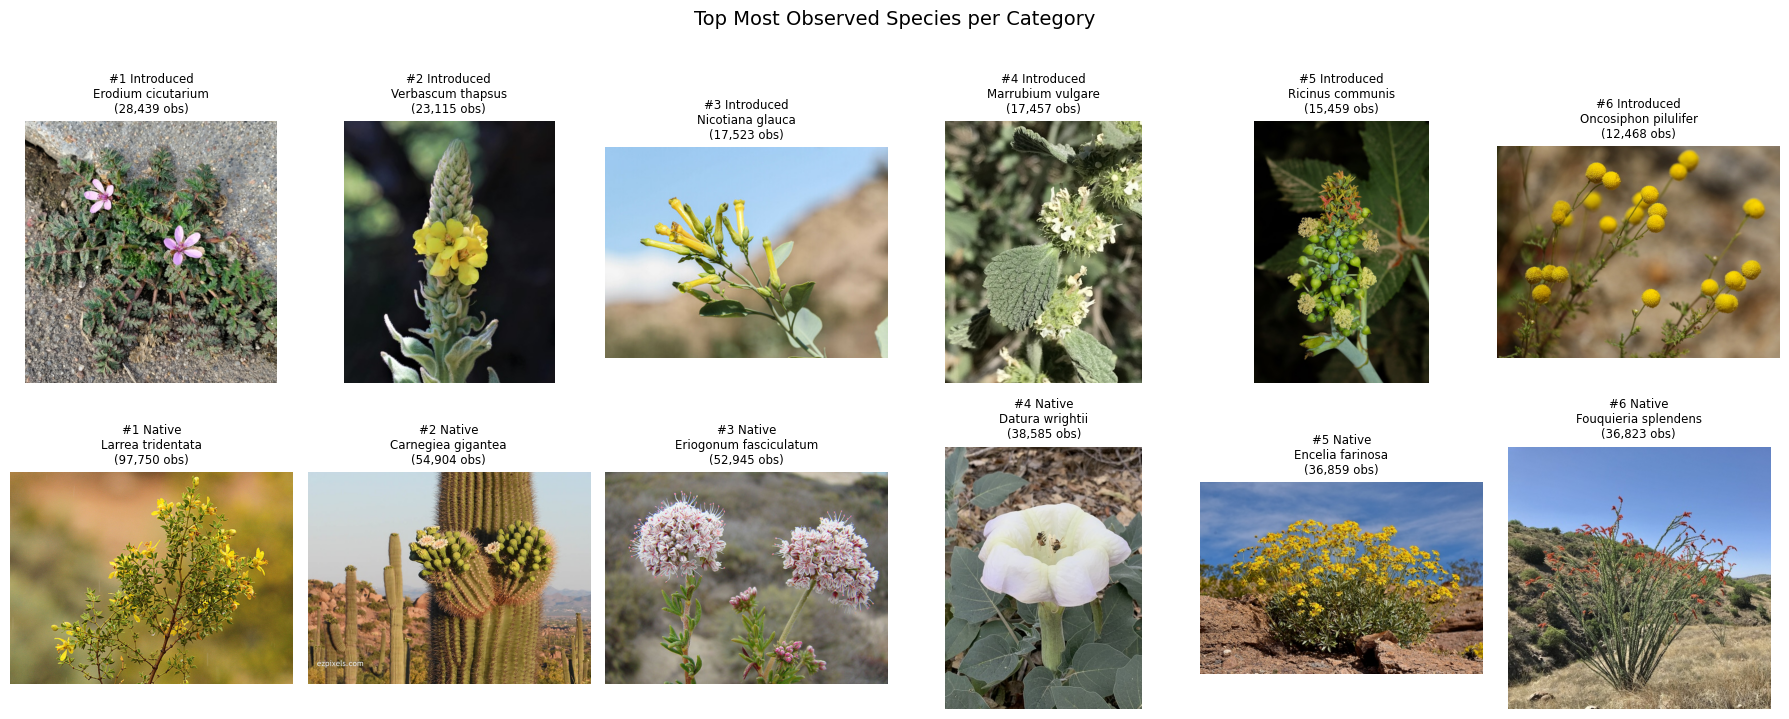

In [28]:
# 1. Interactive HTML Table with Thumbnails
def display_species_table(df, label, top_n=15):
    sub = df[df.label == label].head(top_n)
    rows = []
    for _, r in sub.iterrows():
        img_html = f'<img src="{r.photo_url}" width="65" height="65" style="object-fit:cover; border-radius:6px;"/>' if pd.notna(r.photo_url) else "No photo"
        rows.append(f'''
        <tr style="border-bottom: 1px solid #e0e0e0; height: 75px;">
            <td style="padding: 6px; font-weight: bold; text-align: center;">#{r.rank_in_class}</td>
            <td style="padding: 6px; text-align: center;">{img_html}</td>
            <td style="padding: 6px;"><i><b>{r.scientific_name}</b></i></td>
            <td style="padding: 6px; color: #555;">{r.common_name or '-'}</td>
            <td style="padding: 6px; text-align: right; font-weight: bold;">{r.observation_count:,}</td>
        </tr>
        ''')
    table_html = f'''
    <div style="margin-bottom: 25px;">
        <h3 style="color: {'#2e7d32' if label=='native' else '#c62828'};">Top {top_n} {label.capitalize()} Plant Species in Bounding Box</h3>
        <table style="width: 100%; border-collapse: collapse; font-family: sans-serif; font-size: 13px;">
            <tr style="background-color: #f5f5f5; border-bottom: 2px solid #ccc; text-align: left;">
                <th style="padding: 8px; width: 60px; text-align: center;">Rank</th>
                <th style="padding: 8px; width: 80px; text-align: center;">Photo</th>
                <th style="padding: 8px;">Scientific Name</th>
                <th style="padding: 8px;">Common Name</th>
                <th style="padding: 8px; text-align: right;">Observations in Box</th>
            </tr>
            {''.join(rows)}
        </table>
    </div>
    '''
    display(HTML(table_html))

for label in CLASSES:
    display_species_table(df_species, label, top_n=12)

# 2. Visual Photo Gallery of Top Species
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(18, 3.5 * len(CLASSES)))
for row, label in zip(axes, CLASSES):
    sub = df_species[df_species.label == label].head(6)
    for ax, (_, sp) in zip(row, sub.iterrows()):
        if pd.notna(sp.photo_url):
            try:
                r = requests.get(sp.photo_url, headers=HEADERS, timeout=10)
                img = Image.open(io.BytesIO(r.content))
                ax.imshow(img)
            except Exception:
                ax.text(0.5, 0.5, "Image error", ha="center")
        ax.set_title(f"#{sp.rank_in_class} {label.capitalize()}\n{sp.scientific_name}\n({sp.observation_count:,} obs)", fontsize=8.5)
        ax.axis("off")
plt.suptitle("Top Most Observed Species per Category", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 6. Histogram: Number of Pictures (Observations) per Species
Examine the abundance curve across all species to evaluate how many species have sufficient observations for training.

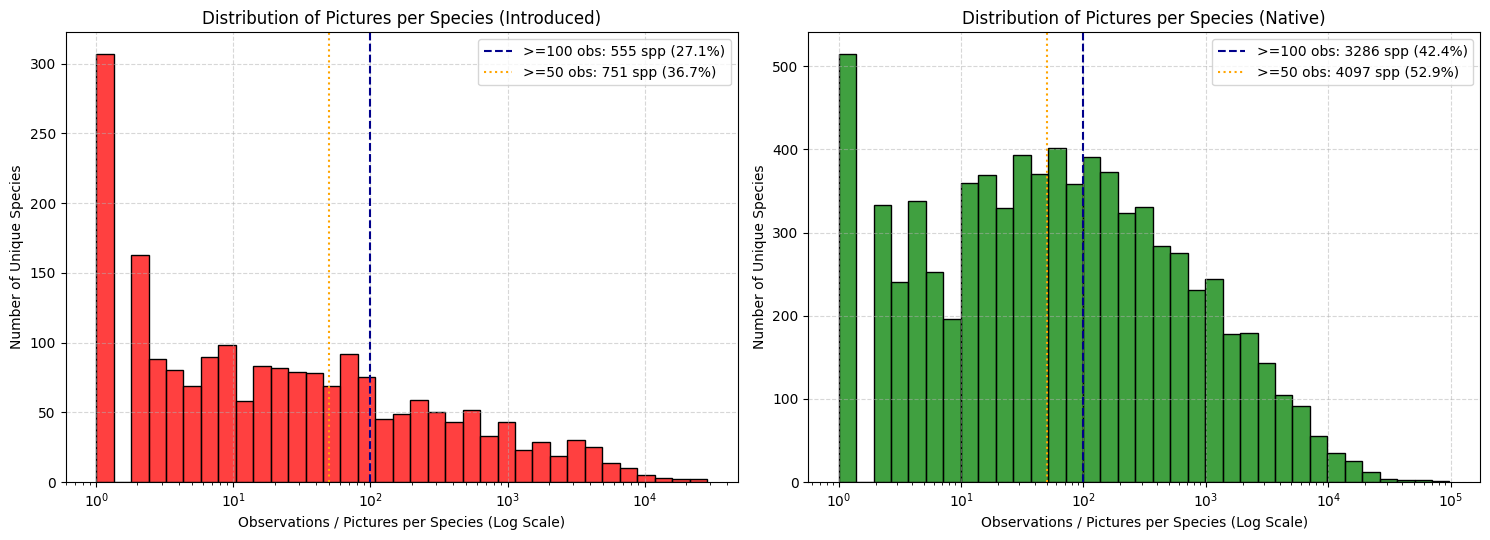

Number of species with at least N observations in BBOX:


,>=10 obs,>=25 obs,>=50 obs,>=100 obs,>=200 obs,>=500 obs,>=1000 obs
introduced,1182,942,751,555,439,283,181
native,5868,4892,4097,3286,2475,1604,1069


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
palette = {"native": "green", "introduced": "red"}

for i, label in enumerate(CLASSES):
    sub = df_species[df_species.label == label]
    sns.histplot(
        data=sub,
        x="observation_count",
        color=palette[label],
        bins=35,
        log_scale=(True, False),
        ax=axes[i],
        edgecolor="black"
    )
    axes[i].set_title(f"Distribution of Pictures per Species ({label.capitalize()})")
    axes[i].set_xlabel("Observations / Pictures per Species (Log Scale)")
    axes[i].set_ylabel("Number of Unique Species")
    axes[i].grid(True, linestyle="--", alpha=0.5)

    # Annotate availability thresholds
    n_total = len(sub)
    n_100 = (sub.observation_count >= 100).sum()
    n_50 = (sub.observation_count >= 50).sum()
    axes[i].axvline(100, color="darkblue", linestyle="--", label=f">=100 obs: {n_100} spp ({n_100/n_total*100:.1f}%)")
    axes[i].axvline(50, color="orange", linestyle=":", label=f">=50 obs: {n_50} spp ({n_50/n_total*100:.1f}%)")
    axes[i].legend(loc="upper right")

plt.tight_layout()
plt.show()

# Print summary table of availability
thresholds = [10, 25, 50, 100, 200, 500, 1000]
print("Number of species with at least N observations in BBOX:")
thresh_df = pd.DataFrame({
    f">={n} obs": [(df_species[df_species.label == l].observation_count >= n).sum() for l in CLASSES]
    for n in thresholds
}, index=CLASSES)
display(thresh_df)

## 7. Configuration: Select Top X Species & Y Pictures per Species
Set the number of species to extract from each category ($X$) and the number of pictures to download per species ($Y$).

In [30]:
# ==============================================================================
# DATASET SELECTION PARAMETERS
# ==============================================================================
TOP_X_INTRODUCED = 100    # Number of top species for Introduced plants
TOP_X_NATIVE = 100        # Number of top species for Native plants
PICS_PER_SPECIES = 500   # Number of pictures/observations to download per species
# ==============================================================================

# Select top X species from each class dynamically using their specific counters
selected_intro = df_species[df_species.label == "introduced"].head(TOP_X_INTRODUCED)
selected_native = df_species[df_species.label == "native"].head(TOP_X_NATIVE)
selected_species = pd.concat([selected_intro, selected_native]).copy()

selected_species_path = os.path.join(META_DIR, "selected_top_species.csv")
selected_species.to_csv(selected_species_path, index=False)

total_target_images = (TOP_X_INTRODUCED + TOP_X_NATIVE) * PICS_PER_SPECIES
print(f"=== Selected Configuration ===")
print(f"Classes                         : {CLASSES}")
print(f"Top species (Introduced)        : {TOP_X_INTRODUCED}")
print(f"Top species (Native)            : {TOP_X_NATIVE}")
print(f"Target pictures per species (Y) : {PICS_PER_SPECIES}")
print(f"Total target images             : {total_target_images:,}")
print(f"Saved selected species list to  : {selected_species_path}\n")

for label, limit in [("introduced", TOP_X_INTRODUCED), ("native", TOP_X_NATIVE)]:
    sub = selected_species[selected_species.label == label]
    min_obs = sub.observation_count.min()
    print(f"[{label.capitalize()}] Selected {len(sub)} species. Lowest observation count in top {limit} is {min_obs:,} obs.")

=== Selected Configuration ===
Classes                         : ['introduced', 'native']
Top species (Introduced)        : 100
Top species (Native)            : 100
Target pictures per species (Y) : 500
Total target images             : 100,000
Saved selected species list to  : /content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_top_species/meta/selected_top_species.csv

[Introduced] Selected 100 species. Lowest observation count in top 100 is 2,400 obs.
[Native] Selected 100 species. Lowest observation count in top 100 is 8,787 obs.


## 8. Targeted Fetching & Download (Top X Species × Y Pictures)
Downloads up to $Y$ photos for each of the top $X$ selected species. This process is fully resumable: if interrupted, re-running this cell skips already downloaded images.

In [31]:
def fetch_and_download_top_species(selected_df, pics_per_species=PICS_PER_SPECIES, download_workers=DOWNLOAD_WORKERS):
    for label in CLASSES:
        img_dir = os.path.join(SAVE_DIR, "images", label)
        os.makedirs(img_dir, exist_ok=True)
        meta_path = os.path.join(META_DIR, f"{label}.jsonl")

        # Read existing metadata to support resuming
        existing_by_species = {}
        if os.path.exists(meta_path):
            with open(meta_path, "r", encoding="utf-8") as f:
                for line in f:
                    if line.strip():
                        m = json.loads(line)
                        sp_id = str(m.get("taxon_id"))
                        existing_by_species.setdefault(sp_id, []).append(m)

        # Filter selected species for this class
        class_species = selected_df[selected_df.label == label]
        print(f"=== Fetching & Downloading {label.upper()} ({len(class_species)} species) ===")

        # Open metadata file in append mode
        with open(meta_path, "a", encoding="utf-8") as f_meta:
            for idx, (_, sp) in enumerate(class_species.iterrows()):
                taxon_id = str(sp["taxon_id"])
                sc_name = sp["scientific_name"]
                already_dl = existing_by_species.get(taxon_id, [])
                needed = pics_per_species - len(already_dl)

                if needed <= 0:
                    print(f"  [{idx+1}/{len(class_species)}] {sc_name} already has {len(already_dl)} images. Skipping.")
                    continue

                print(f"  [{idx+1}/{len(class_species)}] {sc_name}: Has {len(already_dl)}, fetching {needed} more...")
                page = 1
                fetched_metadata = []

                while len(fetched_metadata) < needed:
                    params = {
                        "taxon_id": taxon_id,
                        "place_id": PLACE_ID,
                        "quality_grade": "research",
                        "license": PHOTO_LICENSES,
                        "per_page": min(200, max(10, needed - len(fetched_metadata))),
                        "page": page,
                        **BBOX
                    }
                    try:
                        data = api_get(API_OBS, params)
                    except Exception as e:
                        print(f"    Error fetching metadata: {e}")
                        break

                    results = data.get("results", [])
                    if not results:
                        break

                    for obs in results:
                        if obs.get("photos"):
                            meta = extract_metadata(obs, label)
                            fetched_metadata.append(meta)
                            if len(fetched_metadata) >= needed:
                                break

                    if len(results) < 200:
                        break
                    page += 1
                    time.sleep(1)

                if not fetched_metadata:
                    print(f"    No new images found for {sc_name}")
                    continue

                # Download images in parallel
                print(f"    Downloading {len(fetched_metadata)} images using {download_workers} workers...")
                success_count = 0
                with ThreadPoolExecutor(max_workers=download_workers) as executor:
                    results_dl = list(executor.map(download_one, fetched_metadata))
                    for meta, success in zip(fetched_metadata, results_dl):
                        if success:
                            f_meta.write(json.dumps(meta) + "\n")
                            success_count += 1

                f_meta.flush()
                print(f"    Successfully downloaded {success_count}/{len(fetched_metadata)} images.")

# Run the fetching pipeline using our updated selected_species list


In [32]:
%%time
fetch_and_download_top_species(selected_species)

=== Fetching & Downloading INTRODUCED (100 species) ===
  [1/100] Erodium cicutarium already has 500 images. Skipping.
  [2/100] Verbascum thapsus: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [3/100] Nicotiana glauca: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [4/100] Marrubium vulgare: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [5/100] Ricinus communis: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [6/100] Oncosiphon pilulifer: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [7/100] Convolvulus arvensis: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [8/100] Cenchrus setaceus: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [9/100] Oxalis pes-caprae: Has 10, fetching 490 more...
    Successfully downloaded 490/490 images.
  [10/100] Foeniculum vulgare: Has 10, fetching 490 more...
 

## 9. Summary + Combined CSV

In [41]:
# ==============================================================================
# SECTION 9: Consolidate and Clean Metadata
# ==============================================================================
import os
import pandas as pd
import json

# 1. Load target checklist to enforce strict filtering
target_species_path = os.path.join(META_DIR, "selected_top_species.csv")
if os.path.exists(target_species_path):
    targets_df = pd.read_csv(target_species_path)
    valid_taxon_ids = set(targets_df["taxon_id"].unique())
else:
    valid_taxon_ids = None
    print("Warning: Target species list not found. Proceeding without active target filtering.")

dfs = []
for label in CLASSES:
    p = os.path.join(META_DIR, f"{label}.jsonl")
    if os.path.exists(p):
        # Read metadata line by line
        records = []
        with open(p, "r", encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    records.append(json.loads(line))

        df_label = pd.DataFrame(records)

        # Deduplicate on observation_id
        df_label = df_label.drop_duplicates(subset="observation_id")

        # Enforce target species list if available
        if valid_taxon_ids is not None:
            df_label = df_label[df_label["taxon_id"].isin(valid_taxon_ids)]

            # Limit to at most PICS_PER_SPECIES per taxon
            df_label = df_label.groupby("taxon_id").head(PICS_PER_SPECIES)

        dfs.append(df_label)

if dfs:
    df = pd.concat(dfs).reset_index(drop=True)
    csv_out = os.path.join(SAVE_DIR, "metadata_all.csv")
    df.to_csv(csv_out, index=False)

    print(f"Saved clean consolidated metadata ({len(df)} images) to {csv_out}")
    print("\nDataset Summary by Class:")
    print(df.groupby("label").agg(
        images=("observation_id", "count"),
        unique_species=("taxon_id", "nunique")
    ))

    for label in CLASSES:
        print(f"\nSpecies representation in downloaded dataset ({label}):")
        print(df[df.label == label]["scientific_name"].value_counts().head(10).to_string())
else:
    print("No downloaded images found yet. Run cell 8 first.")

Saved clean consolidated metadata (77464 images) to /content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_top_species/metadata_all.csv

Dataset Summary by Class:
            images  unique_species
label                             
introduced   39964             100
native       37500             100

Species representation in downloaded dataset (introduced):
scientific_name
Erodium cicutarium      400
Verbascum thapsus       400
Nicotiana glauca        400
Marrubium vulgare       400
Ricinus communis        400
Oncosiphon pilulifer    400
Convolvulus arvensis    400
Cenchrus setaceus       400
Oxalis pes-caprae       400
Foeniculum vulgare      400

Species representation in downloaded dataset (native):
scientific_name
Larrea tridentata          400
Carnegiea gigantea         400
Datura wrightii            400
Ferocactus cylindraceus    400
Pinus brachyptera          400
Encelia californica        400
Artemisia californica      400
Ferocactus wislizeni      

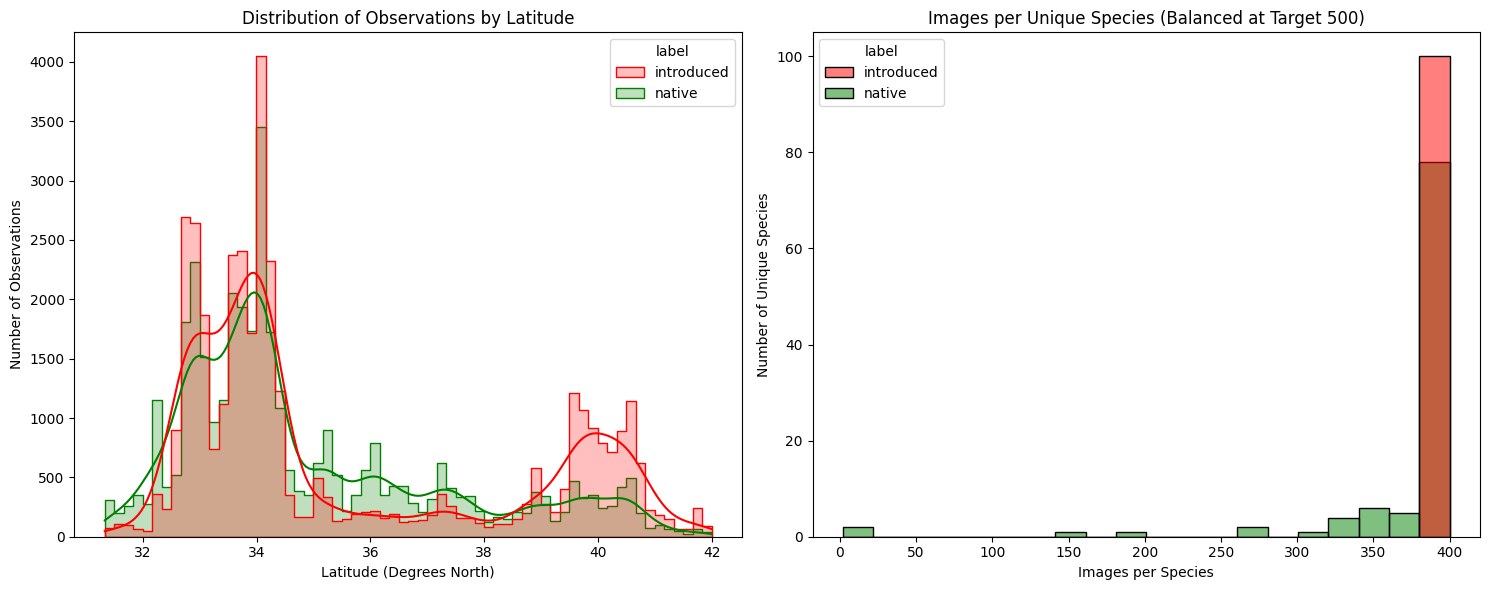

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histogram 1: Latitudinal distribution
sns.histplot(
    data=df,
    x="latitude",
    hue="label",
    kde=True,
    element="step",
    stat="count",
    common_norm=False,
    palette={"introduced": "red", "native": "green"},
    ax=axes[0]
)
axes[0].set_title("Distribution of Observations by Latitude")
axes[0].set_xlabel("Latitude (Degrees North)")
axes[0].set_ylabel("Number of Observations")

# Histogram 2: Images per species in dataset (confirming balance at Y)
species_counts = df.groupby(["label", "scientific_name"]).size().reset_index(name="count")
sns.histplot(
    data=species_counts,
    x="count",
    hue="label",
    element="bars",
    stat="count",
    bins=20,
    common_norm=False,
    palette={"introduced": "red", "native": "green"},
    ax=axes[1]
)
axes[1].set_title(f"Images per Unique Species (Balanced at Target {PICS_PER_SPECIES})")
axes[1].set_xlabel("Images per Species")
axes[1].set_ylabel("Number of Unique Species")

plt.tight_layout()
plt.show()

## 10. Map of Observations

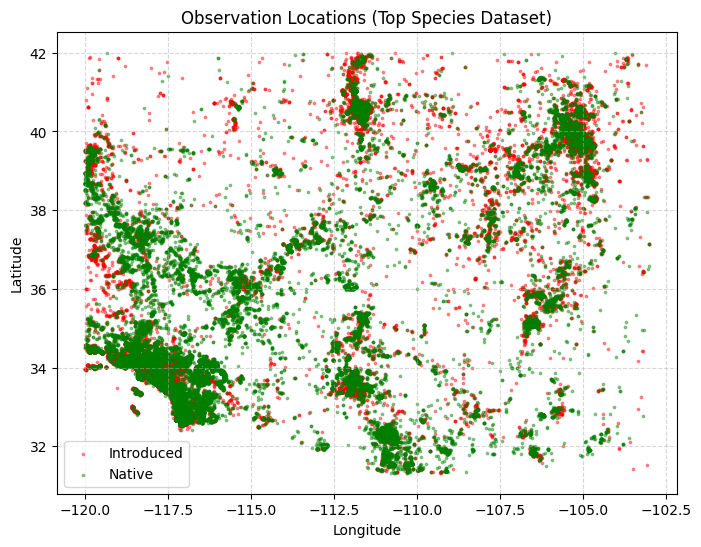

In [43]:
plt.figure(figsize=(8, 6))
for label, color in zip(CLASSES, ["red", "green"]):
    d = df[df.label == label]
    plt.scatter(d.longitude, d.latitude, s=3, alpha=0.4, c=color, label=label.capitalize())
plt.legend()
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Observation Locations (Top Species Dataset)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 11. Random Sample from Each Class

In [44]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(18, 3.5 * len(CLASSES)))
for row, label in zip(axes, CLASSES):
    sub = df[df.label == label]
    sample = sub.sample(min(6, len(sub)))
    for ax, (_, m) in zip(row, sample.iterrows()):
        img_path = os.path.join(SAVE_DIR, m.image_path)
        if os.path.exists(img_path):
            ax.imshow(Image.open(img_path))
            ax.set_title(f"{label.capitalize()}\n{m.scientific_name}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 12. Geographic Overlays (US Map & Satellite Imagery)

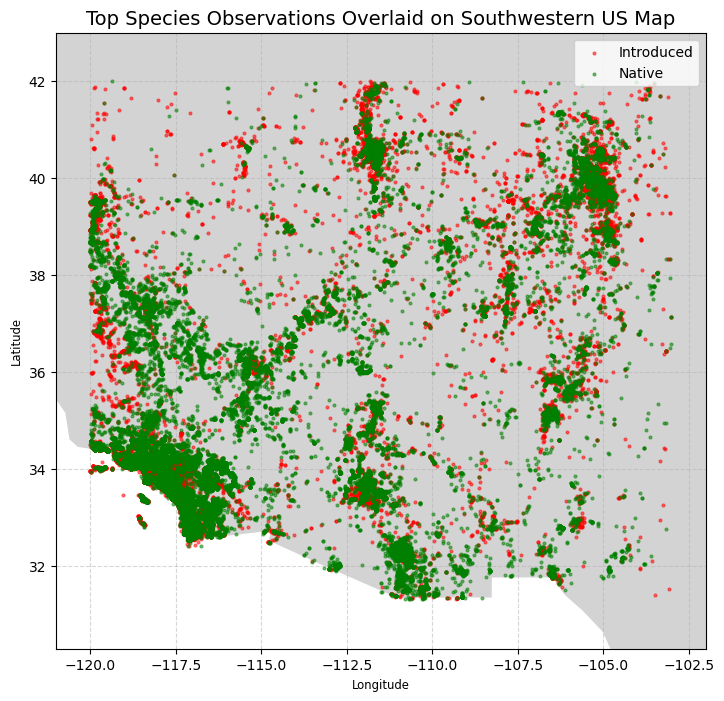

In [45]:
import geopandas as gpd
import matplotlib.pyplot as plt

# US Country Outline Map
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
world = gpd.read_file(url)
usa = world[world.NAME == "United States of America"]

fig, ax = plt.subplots(figsize=(10, 8))
usa.plot(ax=ax, color='lightgray', edgecolor='white', zorder=1)

for label, color in zip(CLASSES, ["red", "green"]):
    d = df[df.label == label]
    ax.scatter(d.longitude, d.latitude, s=4, alpha=0.5, c=color, label=label.capitalize(), zorder=2)

ax.set_xlim(BBOX["swlng"] - 1, BBOX["nelng"] + 1)
ax.set_ylim(BBOX["swlat"] - 1, BBOX["nelat"] + 1)
ax.set_title("Top Species Observations Overlaid on Southwestern US Map", fontsize=14)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")
plt.show()

In [46]:
!pip install -q contextily geopandas

In [47]:
# Satellite imagery basemap overlay
import sys
try:
    import geopandas as gpd
    import contextily as cx
except ImportError:
    print("Installing missing mapping libraries...")
    !{sys.executable} -m pip install -q contextily geopandas
    import geopandas as gpd
    import contextily as cx

import matplotlib.pyplot as plt

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs="EPSG:4326"  # WGS84
)
gdf_web = gdf.to_crs(epsg=3857)  # Web Mercator

fig, ax = plt.subplots(figsize=(12, 10))

for label, color in zip(CLASSES, ["red", "green"]):
    d = gdf_web[gdf_web.label == label]
    d.plot(ax=ax, color=color, markersize=5, alpha=0.6, label=label.capitalize(), zorder=2)

xmin, ymin = gpd.GeoSeries([gpd.points_from_xy([BBOX["swlng"]], [BBOX["swlat"]])[0]], crs="EPSG:4326").to_crs(epsg=3857).x[0], \
             gpd.GeoSeries([gpd.points_from_xy([BBOX["swlng"]], [BBOX["swlat"]])[0]], crs="EPSG:4326").to_crs(epsg=3857).y[0]
xmax, ymax = gpd.GeoSeries([gpd.points_from_xy([BBOX["nelng"]], [BBOX["nelat"]])[0]], crs="EPSG:4326").to_crs(epsg=3857).x[0], \
             gpd.GeoSeries([gpd.points_from_xy([BBOX["nelng"]], [BBOX["nelat"]])[0]], crs="EPSG:4326").to_crs(epsg=3857).y[0]

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery, zorder=1)
ax.set_axis_off()
ax.set_title("Top Species Plant Observations Overlaid on Satellite Imagery (Southwest US)", fontsize=14, pad=10)
ax.legend(loc="upper right", markerscale=2)

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [48]:
# ==============================================================================
# DIAGNOSTICS: Inspecting raw jsonl files and comparing to target checklist
# ==============================================================================
import json
import os
import pandas as pd

# 1. Load targets
targets_df = pd.read_csv(selected_species_path)
target_ids_native = set(targets_df[targets_df.label == 'native']['taxon_id'].astype(str))
target_ids_intro = set(targets_df[targets_df.label == 'introduced']['taxon_id'].astype(str))

print(f"Target species count from CSV - Native: {len(target_ids_native)}, Introduced: {len(target_ids_intro)}")

# 2. Inspect native metadata
native_jsonl = os.path.join(META_DIR, "native.jsonl")

if os.path.exists(native_jsonl):
    with open(native_jsonl, 'r', encoding='utf-8') as f:
        raw_records = [json.loads(line) for line in f if line.strip()]

    raw_df = pd.DataFrame(raw_records)
    print(f"\n--- Raw Native Metadata File Info ---")
    print(f"Total records in native.jsonl       : {len(raw_df)}")
    print(f"Unique observation IDs              : {raw_df['observation_id'].nunique()}")
    print(f"Unique taxon (species) IDs          : {raw_df['taxon_id'].nunique()}")

    # Check for species present in jsonl that are NOT in current TOP_X targets
    raw_df['taxon_id_str'] = raw_df['taxon_id'].astype(str)
    non_target_species = raw_df[~raw_df['taxon_id_str'].isin(target_ids_native)]

    print(f"Records belonging to non-target spp : {len(non_target_species)}")
    print(f"Unique non-target species found     : {non_target_species['taxon_id'].nunique()}")
    if not non_target_species.empty:
        print("\nExamples of non-target species in your file:")
        display(non_target_species[['scientific_name', 'taxon_id']].drop_duplicates().head(10))
else:
    print("native.jsonl not found.")

Target species count from CSV - Native: 100, Introduced: 100

--- Raw Native Metadata File Info ---
Total records in native.jsonl       : 50019
Unique observation IDs              : 40000
Unique taxon (species) IDs          : 213
Records belonging to non-target spp : 3085
Unique non-target species found     : 113

Examples of non-target species in your file:


,scientific_name,taxon_id
57,Fouquieria splendens splendens,79854
61,Echinocereus engelmannii engelmannii,181747
80,Opuntia basilaris basilaris,81156
1115,Eriogonum fasciculatum polifolium,58272
1136,Eriogonum fasciculatum foliolosum,58980
1448,Eriogonum fasciculatum fasciculatum,80781
2207,Encelia farinosa farinosa,240497
3066,Echinocereus engelmannii fasciculatus,856951
3239,Echinocereus engelmannii magnursensis,966988
4061,Opuntia basilaris treleasei,81158
